# TEST PRATIQUE - AI & Automation Engineer
## Surveillance transactionnelle AML/CFT

## Objectif
Construire un prototype de surveillance transactionnelle capable de :
1. Contrôler la qualité des données.
2. Identifier les transactions exploitables.
3. Détecter les comportements atypiques par des règles métier.
4. Identifier les anomalies statistiques par Machine Learning non supervisé.
5. Produire des alertes explicables et exploitables par les analystes.

## Périmètre
- Données synthétiques.
- Transactions digitales.
- Devise : MGA.
- Détection sur les transactions SUCCESS.
- Analyse temporelle basée sur event_time.
- Les alertes sont des signaux à investiguer, pas des preuves d'infraction.

#### 1. IMPORTATION DES BIBLIOTHÈQUES

In [3]:
# Manipulation et analyse des données
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning non supervisé
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

# Gestion des dates
from datetime import timedelta

# Fenêtre glissante
from collections import defaultdict, deque

# Gestion des fichiers et configuration
import os
import json
import warnings

# Affichage des tableaux
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Configuration graphique
sns.set_theme(style="whitegrid")

# Suppression des avertissements non essentiels
warnings.filterwarnings("ignore")

print("Bibliothèques importées avec succès.")

Bibliothèques importées avec succès.


#### 2. CONFIGURATION DU PROJET

In [4]:
# Chemin du dataset
DATA_PATH = "dataset_transactions_AML_5Mo.csv"

# Répertoire des résultats
OUTPUT_DIR = "outputs"

# Répertoire des données filtrés
OUTPUT_DATA = "data/processed"

# Création du dossier de sortie s'il n'existe pas
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(OUTPUT_DATA, exist_ok=True)

# Paramètres temporels des règles
WINDOW_MINUTES = 60

# Paramètres R01 : fractionnement
R01_MIN_TRANSACTIONS = 5
R01_MAX_AMOUNT = 1_000_000
R01_MIN_TOTAL = 4_000_000

# Paramètres R02 : concentration entrante
R02_MIN_SENDERS = 5
R02_WINDOW_MINUTES = 60

# Paramètres R03 : sortie rapide
# Le montant total des sorties représente plus de 80 % du montant total des entrées.
R03_MIN_RATIO = 0.80
# Le montant total des sorties ne dépasse pas le montant total des entrées (ratio ≤ 100 %).
R03_MAX_RATIO = 1.00

# Paramètres Isolation Forest
CONTAMINATION = 0.02
RANDOM_STATE = 42

print("Configuration chargée.")

Configuration chargée.


### EXERCICE A - INGESTION ET QUALITÉ DES DONNÉES

#### 3. CHARGEMENT DU DATASET

In [5]:
# Chargement du fichier CSV
df_raw = pd.read_csv(DATA_PATH)

# Création d'une copie pour conserver les données originales
df = df_raw.copy()

# Affichage des dimensions
print("Nombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])

# Affichage des premières lignes
display(df.head())

# Affichage des noms de colonnes
print("\nColonnes disponibles :")
print(df.columns.tolist())

Nombre de lignes : 40412
Nombre de colonnes : 14


,transaction_id,event_time,ingestion_time,sender_id,receiver_id,amount_mga,transaction_type,channel,status,sender_segment,receiver_segment,sender_kyc_risk,country_code,currency
0,TX000034503,2026-09-26T20:30:51,2026-09-26T20:39:08,CUS01507,CUS00009,713800.0,P2P,API,SUCCESS,AGENT,MERCHANT,MEDIUM,MG,MGA
1,TX000035718,2026-09-07T19:57:18,2026-09-07T20:23:55,CUS01098,CUS01978,55500.0,P2P,USSD,SUCCESS,PERSONAL,MERCHANT,HIGH,MG,MGA
2,TX000004728,2026-09-14T10:33:06,2026-09-14T11:01:31,CUS00697,CUS00077,188700.0,P2P,USSD,SUCCESS,MERCHANT,MERCHANT,LOW,MG,MGA
3,TX000023473,2026-09-02T18:58:02,2026-09-02T19:18:42,CUS01379,CUS01511,180500.0,P2P,USSD,SUCCESS,MERCHANT,PERSONAL,LOW,MG,MGA
4,TX000003571,2026-09-03T09:34:14,2026-09-03T09:45:40,CUS00263,CUS00637,246000.0,P2P,APP,SUCCESS,AGENT,AGENT,LOW,MG,MGA



Colonnes disponibles :
['transaction_id', 'event_time', 'ingestion_time', 'sender_id', 'receiver_id', 'amount_mga', 'transaction_type', 'channel', 'status', 'sender_segment', 'receiver_segment', 'sender_kyc_risk', 'country_code', 'currency']


#### 4. CONTRÔLE DU SCHÉMA

In [6]:
# Définition des colonnes obligatoires
REQUIRED_COLUMNS = [
    "transaction_id",
    "event_time",
    "ingestion_time",
    "sender_id",
    "receiver_id",
    "amount_mga",
    "transaction_type",
    "channel",
    "status",
    "sender_segment",
    "receiver_segment",
    "sender_kyc_risk",
    "country_code",
    "currency"
]

# Identification des colonnes absentes
missing_columns = [
    col for col in REQUIRED_COLUMNS
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Colonnes obligatoires absentes : {missing_columns}"
    )

print("Le schéma est conforme.")

Le schéma est conforme.


#### 5. CONVERSION DES TYPES

In [7]:
# Conversion des dates en datetime
df["event_time"] = pd.to_datetime(
    df["event_time"],
    errors="coerce"
)

df["ingestion_time"] = pd.to_datetime(
    df["ingestion_time"],
    errors="coerce"
)

# Conversion du montant en numérique
df["amount_mga"] = pd.to_numeric(
    df["amount_mga"],
    errors="coerce"
)

# Nettoyage des espaces sur les champs textuels
text_columns = [
    "transaction_id",
    "sender_id",
    "receiver_id",
    "transaction_type",
    "channel",
    "status",
    "sender_segment",
    "receiver_segment",
    "sender_kyc_risk",
    "country_code",
    "currency"
]

for col in text_columns:
    df[col] = df[col].astype("string").str.strip()

print("Conversion des types terminée.")

display(df.dtypes)

Conversion des types terminée.


transaction_id              string
event_time          datetime64[us]
ingestion_time      datetime64[us]
sender_id                   string
receiver_id                 string
amount_mga                 float64
transaction_type            string
channel                     string
status                      string
sender_segment              string
receiver_segment            string
sender_kyc_risk             string
country_code                string
currency                    string
dtype: object

#### 6. ANALYSE DES VALEURS MANQUANTES

In [8]:
# Calcul du nombre de valeurs manquantes par colonne
missing_values = df.isnull().sum()

# Calcul du pourcentage de valeurs manquantes
missing_percentage = (
    df.isnull().sum() / len(df) * 100
).round(2)

# Création du rapport
missing_report = pd.DataFrame({
    "column": missing_values.index,
    "missing_count": missing_values.values,
    "missing_percentage": missing_percentage.values
})

# Affichage uniquement des colonnes contenant des anomalies
display(
    missing_report[
        missing_report["missing_count"] > 0
    ]
)

,column,missing_count,missing_percentage
3,sender_id,15,0.04
5,amount_mga,12,0.03


#### 7. DÉTECTION DES DOUBLONS

In [9]:
# Recherche des transaction_id dupliqués
duplicate_mask = df.duplicated(
    subset=["transaction_id"],
    keep=False
)

# Extraction des doublons
df_duplicates = df[duplicate_mask].copy()

# Nombre de lignes dupliquées
print(
    "Nombre de lignes impliquées dans des doublons :",
    len(df_duplicates)
)

# Nombre d'identifiants distincts concernés
print(
    "Nombre de transaction_id dupliqués :",
    df_duplicates["transaction_id"].nunique()
)

display(
    df_duplicates.sort_values("transaction_id").head(20)
)

Nombre de lignes impliquées dans des doublons : 24
Nombre de transaction_id dupliqués : 12


,transaction_id,event_time,ingestion_time,sender_id,receiver_id,amount_mga,transaction_type,channel,status,sender_segment,receiver_segment,sender_kyc_risk,country_code,currency
40254,TX000000501,2026-09-28 05:02:18,2026-09-28 05:22:18,CUS00212,CUS02099,112200.0,P2P,USSD,SUCCESS,PERSONAL,MERCHANT,LOW,MG,MGA
9982,TX000000501,2026-09-28 05:02:18,2026-09-28 05:22:18,CUS00212,CUS02099,112200.0,P2P,USSD,SUCCESS,PERSONAL,MERCHANT,LOW,MG,MGA
11713,TX000000502,2026-09-07 15:11:12,2026-09-07 15:13:19,CUS00534,CUS02116,111500.0,CASH_OUT,AGENT,SUCCESS,PERSONAL,PERSONAL,LOW,MG,MGA
15823,TX000000502,2026-09-07 15:11:12,2026-09-07 15:13:19,CUS00534,CUS02116,111500.0,CASH_OUT,AGENT,SUCCESS,PERSONAL,PERSONAL,LOW,MG,MGA
28429,TX000000503,2026-09-13 03:32:33,2026-09-13 03:50:49,CUS01394,CUS01692,179300.0,P2M,API,SUCCESS,PERSONAL,PERSONAL,MEDIUM,MG,MGA
31952,TX000000503,2026-09-13 03:32:33,2026-09-13 03:50:49,CUS01394,CUS01692,179300.0,P2M,API,SUCCESS,PERSONAL,PERSONAL,MEDIUM,MG,MGA
15397,TX000000504,2026-09-14 15:20:31,2026-09-14 15:50:10,CUS01428,CUS01753,36400.0,P2P,USSD,SUCCESS,AGENT,AGENT,LOW,MG,MGA
3426,TX000000504,2026-09-14 15:20:31,2026-09-14 15:50:10,CUS01428,CUS01753,36400.0,P2P,USSD,SUCCESS,AGENT,AGENT,LOW,MG,MGA
14566,TX000000505,2026-09-25 18:38:32,2026-09-25 19:00:45,CUS00476,CUS01966,58800.0,P2P,AGENT,SUCCESS,MERCHANT,PERSONAL,MEDIUM,MG,MGA
15310,TX000000505,2026-09-25 18:38:32,2026-09-25 19:00:45,CUS00476,CUS01966,58800.0,P2P,AGENT,SUCCESS,MERCHANT,PERSONAL,MEDIUM,MG,MGA


#### 8. DÉTECTION DES MONTANTS INVALIDES

In [10]:
# Montants manquants
mask_amount_missing = df["amount_mga"].isna()

# Montants nuls ou négatifs
mask_amount_invalid = df["amount_mga"] <= 0

# Extraction des transactions concernées
df_invalid_amounts = df[
    mask_amount_missing | mask_amount_invalid
].copy()

print(
    "Transactions avec montant manquant ou invalide :",
    len(df_invalid_amounts)
)

display(
    df_invalid_amounts[
        ["transaction_id", "amount_mga", "status"]
    ].head(20)
)

Transactions avec montant manquant ou invalide : 20


,transaction_id,amount_mga,status
510,TX000001003,NaN,SUCCESS
7146,TX000001203,-500.0,SUCCESS
8824,TX000001010,NaN,SUCCESS
10392,TX000001205,-500.0,SUCCESS
12073,TX000001009,NaN,SUCCESS
12702,TX000001206,-500.0,SUCCESS
12820,TX000001011,NaN,SUCCESS
15716,TX000001012,NaN,SUCCESS
15833,TX000001007,NaN,SUCCESS
16946,TX000001005,NaN,SUCCESS


#### 9. ANALYSE DES RETARDS DE RÉCEPTION

In [11]:
# Calcul du délai entre l'événement métier et sa réception
df["ingestion_delay_minutes"] = (
    df["ingestion_time"] - df["event_time"]
).dt.total_seconds() / 60

# Détection des dates invalides
mask_invalid_dates = (
    df["event_time"].isna()
    | df["ingestion_time"].isna()
)

# Détection d'une ingestion antérieure à l'événement
mask_negative_delay = (
    df["ingestion_delay_minutes"] < 0
)

# Seuil de retard opérationnel utilisé pour l'analyse
LATE_THRESHOLD_MINUTES = 30

mask_late_transactions = (
    df["ingestion_delay_minutes"]
    > LATE_THRESHOLD_MINUTES
)

print(
    "Transactions avec retard supérieur à 30 minutes :",
    mask_late_transactions.sum()
)

print(
    "Transactions avec dates invalides :",
    mask_invalid_dates.sum()
)

print(
    "Transactions avec délai négatif :",
    mask_negative_delay.sum()
)

# Statistiques descriptives des retards
display(
    df["ingestion_delay_minutes"].describe()
)

# # Sélection des 5 lignes avec les plus grands retards d'ingestion
# top_5_delays = df.nlargest(5, "ingestion_delay_minutes")

# # Affichage des colonnes clés pour comprendre le problème
# print("\nTop 5 des transactions ayant les plus grands retards d'ingestion :")
# display(
#     top_5_delays[
#         [
#             "sender_id",
#             "amount_mga",
#             "event_time",
#             "ingestion_time",
#             "ingestion_delay_minutes",
#         ]
#     ]
# )


Transactions avec retard supérieur à 30 minutes : 20
Transactions avec dates invalides : 0
Transactions avec délai négatif : 0


count    40412.000000
mean        17.042568
std         96.143553
min          0.000000
25%          7.366667
50%         14.900000
75%         22.416667
max       4320.000000
Name: ingestion_delay_minutes, dtype: float64

#### 10. RAPPORT GLOBAL DE QUALITÉ

In [12]:
quality_metrics = {
    "total_transactions": len(df),

    "duplicate_transaction_rows":
        int(duplicate_mask.sum()),

    "missing_sender_id":
        int(df["sender_id"].isna().sum()),

    "missing_receiver_id":
        int(df["receiver_id"].isna().sum()),

    "missing_amount":
        int(mask_amount_missing.sum()),

    "invalid_amount":
        int(mask_amount_invalid.sum()),

    "invalid_event_time":
        int(df["event_time"].isna().sum()),

    "invalid_ingestion_time":
        int(df["ingestion_time"].isna().sum()),

    "late_transactions":
        int(mask_late_transactions.sum()),

    "negative_ingestion_delay":
        int(mask_negative_delay.sum())
}

quality_report = pd.DataFrame(
    quality_metrics.items(),
    columns=["quality_metric", "value"]
)

display(quality_report)

# Export du rapport
quality_report.to_csv(
    os.path.join(OUTPUT_DIR, "quality_report.csv"),
    index=False,
    encoding="utf-8"
)

print("Rapport de qualité exporté.")

,quality_metric,value
0,total_transactions,40412
1,duplicate_transaction_rows,24
2,missing_sender_id,15
3,missing_receiver_id,0
4,missing_amount,12
5,invalid_amount,8
6,invalid_event_time,0
7,invalid_ingestion_time,0
8,late_transactions,20
9,negative_ingestion_delay,0


Rapport de qualité exporté.


#### 11. PRÉPARATION DES DONNÉES EXPLOITABLES

In [13]:
# Création d'un masque regroupant les anomalies bloquantes
mask_quarantine = (
    duplicate_mask
    | mask_amount_missing
    | mask_amount_invalid
    | mask_invalid_dates
    | mask_negative_delay
    | df["sender_id"].isna()
    | df["receiver_id"].isna()
    | df["transaction_id"].isna()
)

# Transactions mises en quarantaine
df_quarantine = df[mask_quarantine].copy()

# Transactions techniquement exploitables
df_clean = df[~mask_quarantine].copy()

print("Transactions initiales :", len(df))
print("Transactions exploitables :", len(df_clean))
print("Transactions en quarantaine :", len(df_quarantine))

# Vérification du rapprochement des volumes
assert len(df) == len(df_clean) + len(df_quarantine)

# Export
df_clean.to_csv(
    os.path.join(OUTPUT_DATA, "transactions_clean.csv"),
    index=False,
    encoding="utf-8"
)

df_quarantine.to_csv(
    os.path.join(OUTPUT_DATA, "transactions_quarantine.csv"),
    index=False,
    encoding="utf-8"
)

print("Exports réalisés.")

Transactions initiales : 40412
Transactions exploitables : 40353
Transactions en quarantaine : 59
Exports réalisés.


#### 12. ANALYSE DES STATUTS

,status,count
0,SUCCESS,38363
1,FAILED,1589
2,REVERSED,401


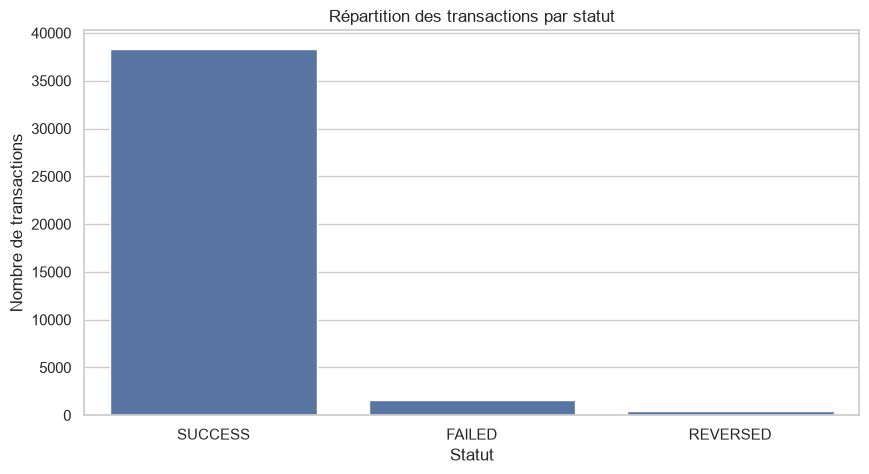

In [14]:
status_distribution = (
    df_clean["status"]
    .value_counts()
    .reset_index()
)

status_distribution.columns = [
    "status",
    "count"
]

display(status_distribution)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=status_distribution,
    x="status",
    y="count"
)

plt.title("Répartition des transactions par statut")
plt.xlabel("Statut")
plt.ylabel("Nombre de transactions")

plt.show()

#### 13. ANALYSE DES TYPES DE TRANSACTIONS

,transaction_type,count
0,P2P,29783
1,P2M,4032
2,CASH_OUT,3325
3,CASH_IN,3213


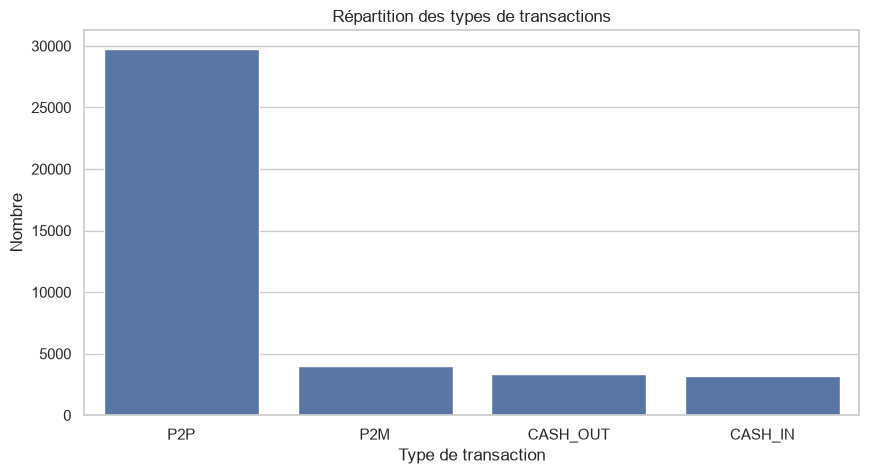

In [15]:
transaction_distribution = (
    df_clean["transaction_type"]
    .value_counts()
    .reset_index()
)

transaction_distribution.columns = [
    "transaction_type",
    "count"
]

display(transaction_distribution)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=transaction_distribution,
    x="transaction_type",
    y="count"
)

plt.title("Répartition des types de transactions")
plt.xlabel("Type de transaction")
plt.ylabel("Nombre")

plt.show()

### EXERCICE B - MOTEUR DE DÉTECTION AML/CFT
Nous appliquons les règles uniquement sur les transactions :
- SUCCESS
- P2P
- avec des identifiants et montants valides
- dont les dates sont exploitables.

#### 14. PRÉPARATION DU DATASET POUR LE MOTEUR AML

In [16]:
# Sélection des transactions réussies de type P2P
df_p2p = df_clean[
    (df_clean["status"] == "SUCCESS")
    & (df_clean["transaction_type"] == "P2P")
].copy()

# Tri chronologique indispensable pour les fenêtres glissantes
df_p2p = df_p2p.sort_values(
    by=["event_time", "transaction_id"] #, ascending=True #ASC|DESC
).reset_index(drop=True)

# Vérification
print("Transactions SUCCESS P2P :", len(df_p2p))

display(
    df_p2p[
        [
            "transaction_id",
            "event_time",
            "sender_id",
            "receiver_id",
            "amount_mga"
        ]
    ].head()
)

Transactions SUCCESS P2P : 28309


,transaction_id,event_time,sender_id,receiver_id,amount_mga
0,TX000027282,2026-09-01 00:00:04,CUS00636,CUS00062,135000.0
1,TX000025945,2026-09-01 00:00:42,CUS00293,CUS00929,98700.0
2,TX000015474,2026-09-01 00:01:03,CUS00784,CUS00850,32600.0
3,TX000019663,2026-09-01 00:01:28,CUS01004,CUS01718,65300.0
4,TX000007300,2026-09-01 00:03:51,CUS01234,CUS01868,97900.0


#### 15. FONCTION DE CRÉATION D'UNE ALERTE

In [17]:
# Cette fonction permet d'uniformiser la structure des alertes
# produites par les différentes règles.

alerts = []

def create_alert(
    rule_id,
    customer_id,
    window_start,
    window_end,
    transactions,
    total_amount,
    explanation
):
    """
    Crée une alerte AML structurée.

    Parameters
    ----------
    rule_id : str
        Identifiant de la règle (R01, R02 ou R03).

    customer_id : str
        Identifiant du client concerné.

    window_start : datetime
        Début de la fenêtre d'analyse.

    window_end : datetime
        Fin de la fenêtre d'analyse.

    transactions : DataFrame
        Transactions utilisées comme éléments de preuve.

    total_amount : float
        Montant total calculé.

    explanation : str
        Explication métier de l'alerte.
    """

    alert = {
        "alert_id": f"{rule_id}_{customer_id}_{window_end}",
        "rule_id": rule_id,
        "customer_id": customer_id,
        "window_start": window_start,
        "window_end": window_end,
        "transaction_count": len(transactions),
        "total_amount_mga": total_amount,
        "evidence_transaction_ids": "|".join(
            transactions["transaction_id"].astype(str)
        ),
        "explanation": explanation
    }

    alerts.append(alert)

#### 16. RÈGLE R01 : FRACTIONNEMENT

Un même émetteur réalise au moins 5 transferts P2P sortants :
- Chaque transaction est strictement inférieure à 1 000 000 MGA.
- Le montant cumulé est strictement supérieur à 4 000 000 MGA.
- Les transactions sont regroupées dans une fenêtre glissante de 60 minutes.

In [18]:
def detect_r01(df_transactions):
    """
    Détecte le fractionnement des transferts sortants.

    R01 :
    - Même émetteur
    - Transactions P2P SUCCESS
    - Montant individuel < 1 000 000 MGA
    - Au moins 5 transactions
    - Montant cumulé > 4 000 000 MGA
    - Fenêtre glissante de 60 minutes
    """

    r01_alerts = []

    # Filtrage des transactions dont le montant individuel respecte le seuil de la règle
    df_rule = df_transactions[
        df_transactions["amount_mga"] < R01_MAX_AMOUNT
    ].copy()

    # Analyse indépendante pour chaque émetteur
    for sender, group in df_rule.groupby("sender_id"):

        # Tri chronologique
        group = group.sort_values("event_time")

        # Index temporel pour rolling
        group = group.set_index("event_time")

        # Fenêtre glissante de 60 minutes
        rolling_count = group["amount_mga"].rolling(
            "60min"
        ).count()

        rolling_sum = group["amount_mga"].rolling(
            "60min"
        ).sum()

        # Conditions R01
        mask_detected = (
            (rolling_count >= R01_MIN_TRANSACTIONS)
            &
            (rolling_sum > R01_MIN_TOTAL)
        )

        # Extraction des points de détection
        detected_times = group.index[mask_detected]

        for detection_time in detected_times:

            # Définition de la fenêtre
            window_start = (
                detection_time - timedelta(minutes=60)
            )

            window_end = detection_time

            # Récupération des transactions de la fenêtre
            transactions_window = group.loc[
                (group.index > window_start)
                & (group.index <= window_end)
            ].reset_index()

            # Vérification exacte des critères
            if (
                len(transactions_window)
                >= R01_MIN_TRANSACTIONS
                and
                transactions_window["amount_mga"].sum()
                > R01_MIN_TOTAL
            ):

                r01_alerts.append({
                    "rule_id": "R01",
                    "customer_id": sender,
                    "window_start": window_start,
                    "window_end": window_end,
                    "transaction_count":
                        len(transactions_window),
                    "total_amount_mga":
                        transactions_window["amount_mga"].sum(),
                    "evidence_transaction_ids":
                        "|".join(
                            transactions_window[
                                "transaction_id"
                            ].astype(str)
                        ),
                    "explanation":
                        "Fractionnement détecté : au moins "
                        "5 transferts P2P sortants individuels "
                        "inférieurs à 1 000 000 MGA, totalisant "
                        "plus de 4 000 000 MGA sur 60 minutes."
                })

    return pd.DataFrame(r01_alerts)

#### 17. EXÉCUTION DE R01

In [19]:
alerts_r01 = detect_r01(df_p2p)

print("Nombre d'alertes R01 :", len(alerts_r01))

display(alerts_r01.head(10))

Nombre d'alertes R01 : 12


,rule_id,customer_id,window_start,window_end,transaction_count,total_amount_mga,evidence_transaction_ids,explanation
0,R01,CUS_STRUCT_00,2026-09-05 09:30:00,2026-09-05 10:30:00,5,4308363.0,TX000000001|TX000000002|TX000000003|TX00000000...,Fractionnement détecté : au moins 5 transferts...
1,R01,CUS_STRUCT_00,2026-09-05 09:35:00,2026-09-05 10:35:00,6,5124814.0,TX000000001|TX000000002|TX000000003|TX00000000...,Fractionnement détecté : au moins 5 transferts...
2,R01,CUS_STRUCT_00,2026-09-05 09:40:00,2026-09-05 10:40:00,7,6048669.0,TX000000001|TX000000002|TX000000003|TX00000000...,Fractionnement détecté : au moins 5 transferts...
3,R01,CUS_STRUCT_01,2026-09-12 09:30:00,2026-09-12 10:30:00,5,4259868.0,TX000000008|TX000000009|TX000000010|TX00000001...,Fractionnement détecté : au moins 5 transferts...
4,R01,CUS_STRUCT_01,2026-09-12 09:35:00,2026-09-12 10:35:00,6,5111008.0,TX000000008|TX000000009|TX000000010|TX00000001...,Fractionnement détecté : au moins 5 transferts...
5,R01,CUS_STRUCT_01,2026-09-12 09:40:00,2026-09-12 10:40:00,7,5940230.0,TX000000008|TX000000009|TX000000010|TX00000001...,Fractionnement détecté : au moins 5 transferts...
6,R01,CUS_STRUCT_02,2026-09-19 09:30:00,2026-09-19 10:30:00,5,4277122.0,TX000000015|TX000000016|TX000000017|TX00000001...,Fractionnement détecté : au moins 5 transferts...
7,R01,CUS_STRUCT_02,2026-09-19 09:35:00,2026-09-19 10:35:00,6,5144572.0,TX000000015|TX000000016|TX000000017|TX00000001...,Fractionnement détecté : au moins 5 transferts...
8,R01,CUS_STRUCT_02,2026-09-19 09:40:00,2026-09-19 10:40:00,7,5934737.0,TX000000015|TX000000016|TX000000017|TX00000001...,Fractionnement détecté : au moins 5 transferts...
9,R01,CUS_STRUCT_03,2026-09-26 09:30:00,2026-09-26 10:30:00,5,4282362.0,TX000000022|TX000000023|TX000000024|TX00000002...,Fractionnement détecté : au moins 5 transferts...


#### 18. RÈGLE R02 : CONCENTRATION ENTRANTE

Un même bénéficiaire reçoit des transferts P2P provenant d'au moins 5 émetteurs distincts dans une fenêtre glissante de 60 minutes.

In [20]:
def detect_r02(df_transactions):
    """
    Détecte une concentration de transferts entrants.

    R02 :
    - Même bénéficiaire
    - Au moins 5 émetteurs distincts
    - Transferts P2P SUCCESS (déjà filtrés en amont)
    - Fenêtre glissante de 60 minutes

    Méthode :
    Sliding Window avec deque et compteur d'émetteurs distincts.
    """
    
    # Initialiser la liste des alertes
    r02_alerts = []

    # --------------------------------------------------
    # 1. ANALYSE PAR BÉNÉFICIAIRE
    # --------------------------------------------------
    # Regrouper les transactions par bénéficiaire
    for receiver, group in df_transactions.groupby("receiver_id"):
        
        # Tri chronologique
        group = group.sort_values("event_time")

        # Transactions actuellement dans la fenêtre
        window = deque()

        # Nombre de transactions par émetteur
        sender_counts = defaultdict(int)
        
        # Nombre d'émetteurs différents
        distinct_senders = 0

        # --------------------------------------------------
        # 2. PARCOURS CHRONOLOGIQUE
        # --------------------------------------------------
        # Parcourir les transactions
        for _, transaction in group.iterrows():

            current_time = transaction["event_time"]
            sender = transaction["sender_id"]

            # Ajouter la transaction courante
            window.append(transaction)

            sender_counts[sender] += 1
            
            # Détecter un nouvel émetteur distinct
            if sender_counts[sender] == 1:
                distinct_senders += 1

            # --------------------------------------------------
            # 3. ÉLIMINER LES TRANSACTIONS HORS FENÊTRE
            # --------------------------------------------------
            # Calculer le début de la fenêtre glissante
            window_start = (
                current_time
                - timedelta(minutes=R02_WINDOW_MINUTES)
            )
            
            # Éliminer les transactions trop anciennes
            while (
                window
                and window[0]["event_time"] <= window_start
            ):
                # Mettre à jour les compteurs après suppression
                old_transaction = window.popleft()

                old_sender = old_transaction["sender_id"]

                sender_counts[old_sender] -= 1
                
                # Supprimer l'émetteur s'il n'a plus de transaction
                if sender_counts[old_sender] == 0:

                    del sender_counts[old_sender]

                    distinct_senders -= 1

            # --------------------------------------------------
            # 4. DÉTECTION R02
            # --------------------------------------------------

            if distinct_senders >= R02_MIN_SENDERS:

                transactions_window = pd.DataFrame(
                    list(window)
                )

                transaction_count = len(
                    transactions_window
                )

                total_amount = transactions_window[
                    "amount_mga"
                ].sum()

                evidence_ids = "|".join(
                    transactions_window[
                        "transaction_id"
                    ].astype(str)
                )

                r02_alerts.append({

                    "rule_id": "R02",

                    "customer_id": receiver,

                    "window_start":
                        transactions_window[
                            "event_time"
                        ].min(),

                    "window_end": current_time,

                    "transaction_count":
                        transaction_count,

                    "total_amount_mga":
                        total_amount,

                    "evidence_transaction_ids":
                        evidence_ids,

                    "explanation":
                        f"Concentration entrante détectée : "
                        f"{distinct_senders} émetteurs distincts "
                        f"ont transféré des fonds au même "
                        f"bénéficiaire sur une fenêtre "
                        f"glissante de {R02_WINDOW_MINUTES} minutes."
                })

    # --------------------------------------------------
    # 5. RESTITUTION
    # --------------------------------------------------

    return pd.DataFrame(r02_alerts)

#### 19. EXÉCUTION DE R02

In [21]:
alerts_r02 = detect_r02(df_p2p)

print("Nombre d'alertes R02 :", len(alerts_r02))

display(alerts_r02.head(10))

Nombre d'alertes R02 : 36


,rule_id,customer_id,window_start,window_end,transaction_count,total_amount_mga,evidence_transaction_ids,explanation
0,R02,CUS_FANIN_00,2026-09-07 11:00:00,2026-09-07 11:12:00,5,2456004.0,TX000000029|TX000000030|TX000000031|TX00000003...,Concentration entrante détectée : 5 émetteurs ...
1,R02,CUS_FANIN_00,2026-09-07 11:00:00,2026-09-07 11:15:00,6,2819215.0,TX000000029|TX000000030|TX000000031|TX00000003...,Concentration entrante détectée : 6 émetteurs ...
2,R02,CUS_FANIN_00,2026-09-07 11:00:00,2026-09-07 11:18:00,7,3295762.0,TX000000029|TX000000030|TX000000031|TX00000003...,Concentration entrante détectée : 7 émetteurs ...
3,R02,CUS_FANIN_00,2026-09-07 11:00:00,2026-09-07 11:21:00,8,3789550.0,TX000000029|TX000000030|TX000000031|TX00000003...,Concentration entrante détectée : 8 émetteurs ...
4,R02,CUS_FANIN_00,2026-09-07 11:00:00,2026-09-07 11:24:00,9,4026489.0,TX000000029|TX000000030|TX000000031|TX00000003...,Concentration entrante détectée : 9 émetteurs ...
5,R02,CUS_FANIN_00,2026-09-07 11:00:00,2026-09-07 11:27:00,10,4472070.0,TX000000029|TX000000030|TX000000031|TX00000003...,Concentration entrante détectée : 10 émetteurs...
6,R02,CUS_FANIN_01,2026-09-14 11:00:00,2026-09-14 11:12:00,5,1612958.0,TX000000039|TX000000040|TX000000041|TX00000004...,Concentration entrante détectée : 5 émetteurs ...
7,R02,CUS_FANIN_01,2026-09-14 11:00:00,2026-09-14 11:15:00,6,1923637.0,TX000000039|TX000000040|TX000000041|TX00000004...,Concentration entrante détectée : 6 émetteurs ...
8,R02,CUS_FANIN_01,2026-09-14 11:00:00,2026-09-14 11:18:00,7,2591086.0,TX000000039|TX000000040|TX000000041|TX00000004...,Concentration entrante détectée : 7 émetteurs ...
9,R02,CUS_FANIN_01,2026-09-14 11:00:00,2026-09-14 11:21:00,8,3211876.0,TX000000039|TX000000040|TX000000041|TX00000004...,Concentration entrante détectée : 8 émetteurs ...


#### 20. RÈGLE R03 : SORTIE RAPIDE

Un compte :
1. Reçoit des transferts P2P.
2. Effectue au moins une sortie P2P dans les 60 minutes suivant sa première entrée.
3. Le total des sorties dans cette période dépasse 80 % du total des entrées.
4. Le montant des sorties ne dépasse pas le montant des entrées.

In [22]:
def detect_r03(df_transactions):
    """
    Détecte les mouvements rapides de fonds.

    R03 :
    - Compte bénéficiaire des entrées P2P
    - Sorties P2P dans les 60 minutes suivant la première entrée
    - Ratio sorties / entrées > 80 %
    - Ratio <= 100 %
    """

    r03_alerts = []

    # Les transactions P2P sont considérées ici comme des transferts entre sender_id et receiver_id.

    # Préparation des entrées et sorties
    incoming = df_transactions[
        ["transaction_id", "event_time",
         "sender_id", "receiver_id", "amount_mga"]
    ].copy()

    outgoing = df_transactions[
        ["transaction_id", "event_time",
         "sender_id", "receiver_id", "amount_mga"]
    ].copy()

    # Analyse par compte bénéficiaire des entrées
    for customer, group_in in incoming.groupby(
        "receiver_id"
    ):

        group_in = group_in.sort_values("event_time")

        # Les sorties du compte correspondent aux lignes
        # dont sender_id est ce compte
        group_out = outgoing[
            outgoing["sender_id"] == customer
        ].sort_values("event_time")

        if group_out.empty:
            continue

        # Analyse de chaque première entrée potentielle
        for _, first_in in group_in.iterrows():

            start_time = first_in["event_time"]

            end_time = (
                start_time + timedelta(minutes=60)
            )

            # Toutes les entrées reçues pendant les 60 minutes
            incoming_window = group_in[
                (group_in["event_time"] >= start_time)
                &
                (group_in["event_time"] <= end_time)
            ]

            # Toutes les sorties effectuées pendant la même fenêtre
            outgoing_window = group_out[
                (group_out["event_time"] >= start_time)
                &
                (group_out["event_time"] <= end_time)
            ]

            # Calcul des montants
            total_in = incoming_window[
                "amount_mga"
            ].sum()

            total_out = outgoing_window[
                "amount_mga"
            ].sum()

            # Protection contre division par zéro
            if total_in <= 0:
                continue

            # Ratio des sorties par rapport aux entrées
            outflow_ratio = total_out / total_in

            # Conditions de la règle
            if (
                len(outgoing_window) >= 1
                and
                outflow_ratio > R03_MIN_RATIO
                and
                outflow_ratio <= R03_MAX_RATIO
            ):

                # Regroupement des preuves
                evidence = pd.concat([
                    incoming_window[
                        ["transaction_id"]
                    ],
                    outgoing_window[
                        ["transaction_id"]
                    ]
                ])

                r03_alerts.append({
                    "rule_id": "R03",
                    "customer_id": customer,
                    "window_start": start_time,
                    "window_end": end_time,
                    "transaction_count":
                        len(evidence),
                    "total_amount_mga":
                        total_out,
                    "evidence_transaction_ids":
                        "|".join(
                            evidence[
                                "transaction_id"
                            ].astype(str)
                        ),
                    "explanation":
                        f"Sortie rapide détectée : le compte "
                        f"a transféré {total_out:,.0f} MGA "
                        f"sur {total_in:,.0f} MGA reçus, "
                        f"soit un ratio de "
                        f"{outflow_ratio:.2%} sur 60 minutes."
                })

    return pd.DataFrame(r03_alerts)

#### 21. EXÉCUTION DE R03

In [23]:
alerts_r03 = detect_r03(df_p2p)

print("Nombre d'alertes R03 :", len(alerts_r03))

display(alerts_r03.head(10))

Nombre d'alertes R03 : 45


,rule_id,customer_id,window_start,window_end,transaction_count,total_amount_mga,evidence_transaction_ids,explanation
0,R03,CUS00015,2026-09-13 15:57:47,2026-09-13 16:57:47,2,200600.0,TX000002958|TX000002958,Sortie rapide détectée : le compte a transféré...
1,R03,CUS00047,2026-09-29 01:00:38,2026-09-29 02:00:38,2,36100.0,TX000026066|TX000036723,Sortie rapide détectée : le compte a transféré...
2,R03,CUS00105,2026-09-14 01:13:01,2026-09-14 02:13:01,2,168000.0,TX000035092|TX000035092,Sortie rapide détectée : le compte a transféré...
3,R03,CUS00116,2026-09-09 06:04:47,2026-09-09 07:04:47,2,48800.0,TX000006066|TX000006066,Sortie rapide détectée : le compte a transféré...
4,R03,CUS00148,2026-09-25 18:09:11,2026-09-25 19:09:11,2,475200.0,TX000038716|TX000038716,Sortie rapide détectée : le compte a transféré...
5,R03,CUS00161,2026-09-08 09:58:05,2026-09-08 10:58:05,2,112300.0,TX000013150|TX000008932,Sortie rapide détectée : le compte a transféré...
6,R03,CUS00163,2026-09-23 06:02:38,2026-09-23 07:02:38,2,516800.0,TX000026962|TX000003999,Sortie rapide détectée : le compte a transféré...
7,R03,CUS00164,2026-09-05 01:26:40,2026-09-05 02:26:40,2,160300.0,TX000027419|TX000035066,Sortie rapide détectée : le compte a transféré...
8,R03,CUS00170,2026-09-09 00:58:14,2026-09-09 01:58:14,2,121500.0,TX000009211|TX000017233,Sortie rapide détectée : le compte a transféré...
9,R03,CUS00187,2026-09-19 17:06:45,2026-09-19 18:06:45,2,160600.0,TX000013791|TX000013791,Sortie rapide détectée : le compte a transféré...


#### 22. CONSOLIDATION DES ALERTES

In [24]:
# Fusion des résultats des trois règles
alerts_all = pd.concat(
    [
        alerts_r01,
        alerts_r02,
        alerts_r03
    ],
    ignore_index=True
)

print("Total des alertes générées :", len(alerts_all))

display(alerts_all.head(10))

Total des alertes générées : 93


,rule_id,customer_id,window_start,window_end,transaction_count,total_amount_mga,evidence_transaction_ids,explanation
0,R01,CUS_STRUCT_00,2026-09-05 09:30:00,2026-09-05 10:30:00,5,4308363.0,TX000000001|TX000000002|TX000000003|TX00000000...,Fractionnement détecté : au moins 5 transferts...
1,R01,CUS_STRUCT_00,2026-09-05 09:35:00,2026-09-05 10:35:00,6,5124814.0,TX000000001|TX000000002|TX000000003|TX00000000...,Fractionnement détecté : au moins 5 transferts...
2,R01,CUS_STRUCT_00,2026-09-05 09:40:00,2026-09-05 10:40:00,7,6048669.0,TX000000001|TX000000002|TX000000003|TX00000000...,Fractionnement détecté : au moins 5 transferts...
3,R01,CUS_STRUCT_01,2026-09-12 09:30:00,2026-09-12 10:30:00,5,4259868.0,TX000000008|TX000000009|TX000000010|TX00000001...,Fractionnement détecté : au moins 5 transferts...
4,R01,CUS_STRUCT_01,2026-09-12 09:35:00,2026-09-12 10:35:00,6,5111008.0,TX000000008|TX000000009|TX000000010|TX00000001...,Fractionnement détecté : au moins 5 transferts...
5,R01,CUS_STRUCT_01,2026-09-12 09:40:00,2026-09-12 10:40:00,7,5940230.0,TX000000008|TX000000009|TX000000010|TX00000001...,Fractionnement détecté : au moins 5 transferts...
6,R01,CUS_STRUCT_02,2026-09-19 09:30:00,2026-09-19 10:30:00,5,4277122.0,TX000000015|TX000000016|TX000000017|TX00000001...,Fractionnement détecté : au moins 5 transferts...
7,R01,CUS_STRUCT_02,2026-09-19 09:35:00,2026-09-19 10:35:00,6,5144572.0,TX000000015|TX000000016|TX000000017|TX00000001...,Fractionnement détecté : au moins 5 transferts...
8,R01,CUS_STRUCT_02,2026-09-19 09:40:00,2026-09-19 10:40:00,7,5934737.0,TX000000015|TX000000016|TX000000017|TX00000001...,Fractionnement détecté : au moins 5 transferts...
9,R01,CUS_STRUCT_03,2026-09-26 09:30:00,2026-09-26 10:30:00,5,4282362.0,TX000000022|TX000000023|TX000000024|TX00000002...,Fractionnement détecté : au moins 5 transferts...


#### 23. DÉDUPLICATION DES ALERTES

In [25]:
def deduplicate_alerts(df_alerts):
    """
    Réduit les alertes redondantes générées par des fenêtres temporelles chevauchantes.

    Stratégie :
    - Même rule_id
    - Même customer_id
    - Fenêtres temporelles chevauchantes
    - Conservation de l'alerte la plus représentative
    """

    if df_alerts.empty:
        return df_alerts.copy()

    # Tri chronologique
    df_sorted = df_alerts.sort_values(
        [
            "rule_id",
            "customer_id",
            "window_start",
            "window_end"
        ]
    ).copy()

    deduplicated = []

    # Traitement indépendant par règle et client
    for (rule, customer), group in df_sorted.groupby(
        ["rule_id", "customer_id"]
    ):

        current_alert = None

        for _, alert in group.iterrows():

            if current_alert is None:
                current_alert = alert.copy()
                continue

            # Chevauchement des fenêtres
            overlap = (
                alert["window_start"]
                <= current_alert["window_end"]
            )

            if overlap:

                # Conserver la fenêtre la plus récente
                # si elle représente un comportement plus complet
                if (
                    alert["total_amount_mga"]
                    >
                    current_alert["total_amount_mga"]
                ):
                    current_alert = alert.copy()

            else:

                deduplicated.append(
                    current_alert.to_dict()
                )

                current_alert = alert.copy()

        # Ajout de la dernière alerte du groupe
        if current_alert is not None:
            deduplicated.append(
                current_alert.to_dict()
            )

    return pd.DataFrame(deduplicated)

#### 24. APPLICATION DE LA DÉDUPLICATION

In [26]:
alerts_deduplicated = deduplicate_alerts(
    alerts_all
)

print("Alertes avant déduplication :", len(alerts_all))
print("Alertes après déduplication :", len(alerts_deduplicated))

display(alerts_deduplicated.head(20))

Alertes avant déduplication : 93
Alertes après déduplication : 57


,rule_id,customer_id,window_start,window_end,transaction_count,total_amount_mga,evidence_transaction_ids,explanation
0,R01,CUS_STRUCT_00,2026-09-05 09:40:00,2026-09-05 10:40:00,7,6048669.0,TX000000001|TX000000002|TX000000003|TX00000000...,Fractionnement détecté : au moins 5 transferts...
1,R01,CUS_STRUCT_01,2026-09-12 09:40:00,2026-09-12 10:40:00,7,5940230.0,TX000000008|TX000000009|TX000000010|TX00000001...,Fractionnement détecté : au moins 5 transferts...
2,R01,CUS_STRUCT_02,2026-09-19 09:40:00,2026-09-19 10:40:00,7,5934737.0,TX000000015|TX000000016|TX000000017|TX00000001...,Fractionnement détecté : au moins 5 transferts...
3,R01,CUS_STRUCT_03,2026-09-26 09:40:00,2026-09-26 10:40:00,7,5981560.0,TX000000022|TX000000023|TX000000024|TX00000002...,Fractionnement détecté : au moins 5 transferts...
4,R02,CUS_FANIN_00,2026-09-07 11:00:00,2026-09-07 11:27:00,10,4472070.0,TX000000029|TX000000030|TX000000031|TX00000003...,Concentration entrante détectée : 10 émetteurs...
5,R02,CUS_FANIN_01,2026-09-14 11:00:00,2026-09-14 11:27:00,10,3971968.0,TX000000039|TX000000040|TX000000041|TX00000004...,Concentration entrante détectée : 10 émetteurs...
6,R02,CUS_FANIN_02,2026-09-21 11:00:00,2026-09-21 11:27:00,10,4199998.0,TX000000049|TX000000050|TX000000051|TX00000005...,Concentration entrante détectée : 10 émetteurs...
7,R02,CUS_FANIN_03,2026-09-28 11:00:00,2026-09-28 11:27:00,10,4552671.0,TX000000059|TX000000060|TX000000061|TX00000006...,Concentration entrante détectée : 10 émetteurs...
8,R02,CUS_PASS_00,2026-09-09 14:00:00,2026-09-09 14:18:00,7,3500000.0,TX000000069|TX000000070|TX000000071|TX00000007...,Concentration entrante détectée : 7 émetteurs ...
9,R02,CUS_PASS_01,2026-09-16 14:00:00,2026-09-16 14:18:00,7,3500000.0,TX000000077|TX000000078|TX000000079|TX00000008...,Concentration entrante détectée : 7 émetteurs ...


#### 25. EXPORT DU FICHIER alerts.csv

In [27]:
alerts_deduplicated.to_csv(
    os.path.join(OUTPUT_DIR, "alerts.csv"),
    index=False,
    encoding="utf-8"
)

print("Fichier alerts.csv généré avec succès.")

Fichier alerts.csv généré avec succès.


#### 26. ANALYSE DES ALERTES PAR RÈGLE

,rule_id,alert_count
0,R03,45
1,R02,8
2,R01,4


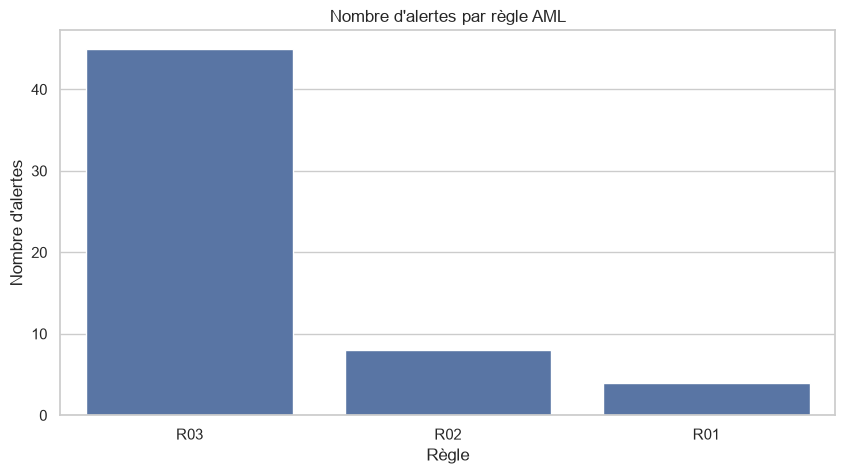

In [28]:
if not alerts_deduplicated.empty:

    alerts_by_rule = (
        alerts_deduplicated["rule_id"]
        .value_counts()
        .reset_index()
    )

    alerts_by_rule.columns = [
        "rule_id",
        "alert_count"
    ]

    display(alerts_by_rule)

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=alerts_by_rule,
        x="rule_id",
        y="alert_count"
    )

    plt.title("Nombre d'alertes par règle AML")
    plt.xlabel("Règle")
    plt.ylabel("Nombre d'alertes")

    plt.show()

else:
    print("Aucune alerte générée.")

### EXERCICE C - IA ET DÉTECTION DES ANOMALIES

#### 27. FEATURE ENGINEERING
Le Machine Learning ne doit pas travailler directement sur les identifiants de transactions. Nous devons construire des features comportementales au niveau client.

Nous allons créer :
- Nombre de transactions envoyées et reçues.
- Montant total envoyé et reçu.
- Montant moyen et maximum.
- Nombre de contreparties distinctes.
- Fréquence des transactions.
- Ratio entre sorties et entrées.

In [29]:
# Transactions SUCCESS, tous types confondus
df_success = df_clean[
    df_clean["status"] == "SUCCESS"
].copy()

# ------------------------------------------------------------
# A. Agrégation des transactions sortantes par client
# ------------------------------------------------------------

outgoing_features = (
    df_success.groupby("sender_id")
    .agg(
        outgoing_count=("transaction_id", "count"),
        outgoing_total=("amount_mga", "sum"),
        outgoing_mean=("amount_mga", "mean"),
        outgoing_max=("amount_mga", "max"),
        outgoing_counterparties=("receiver_id", "nunique")
    )
)

outgoing_features.index.name = "customer_id"

# ------------------------------------------------------------
# B. Agrégation des transactions entrantes par client
# ------------------------------------------------------------

incoming_features = (
    df_success.groupby("receiver_id")
    .agg(
        incoming_count=("transaction_id", "count"),
        incoming_total=("amount_mga", "sum"),
        incoming_mean=("amount_mga", "mean"),
        incoming_max=("amount_mga", "max"),
        incoming_counterparties=("sender_id", "nunique")
    )
)

incoming_features.index.name = "customer_id"

# ------------------------------------------------------------
# C. Fusion des indicateurs entrants et sortants
# ------------------------------------------------------------

customer_features = outgoing_features.join(
    incoming_features,
    how="outer"
)

# Remplacement des valeurs manquantes par 0
customer_features = customer_features.fillna(0)

# ------------------------------------------------------------
# D. Calcul des indicateurs complémentaires
# ------------------------------------------------------------

customer_features["total_transactions"] = (
    customer_features["outgoing_count"]
    +
    customer_features["incoming_count"]
)

customer_features["total_amount"] = (
    customer_features["outgoing_total"]
    +
    customer_features["incoming_total"]
)

# Ratio des sorties par rapport aux entrées
customer_features["outgoing_incoming_ratio"] = (
    customer_features["outgoing_total"]
    /
    customer_features["incoming_total"].replace(0, np.nan)
)

# Remplacement des ratios infinis ou manquants
customer_features[
    "outgoing_incoming_ratio"
] = customer_features[
    "outgoing_incoming_ratio"
].replace(
    [np.inf, -np.inf],
    np.nan
).fillna(0)

# Affichage des features
display(customer_features.head(10))

print(
    "Nombre de clients analysés :",
    len(customer_features)
)

,outgoing_count,outgoing_total,outgoing_mean,outgoing_max,outgoing_counterparties,incoming_count,incoming_total,incoming_mean,incoming_max,incoming_counterparties,total_transactions,total_amount,outgoing_incoming_ratio
customer_id,,,,,,,,,,,,,
CUS00001,22.0,4775900.0,217086.363636,732200.0,22.0,20.0,2950500.0,147525.000000,435700.0,20.0,42.0,7726400.0,1.618675
CUS00002,22.0,3236000.0,147090.909091,416400.0,22.0,15.0,2618400.0,174560.000000,408000.0,15.0,37.0,5854400.0,1.235869
CUS00003,17.0,4403600.0,259035.294118,1499700.0,17.0,18.0,3656200.0,203122.222222,814600.0,18.0,35.0,8059800.0,1.204420
CUS00004,23.0,3258600.0,141678.260870,402500.0,23.0,15.0,2215800.0,147720.000000,858800.0,15.0,38.0,5474400.0,1.470620
CUS00005,18.0,2822900.0,156827.777778,459500.0,18.0,14.0,1945700.0,138978.571429,333000.0,14.0,32.0,4768600.0,1.450840
CUS00006,27.0,5257000.0,194703.703704,489000.0,26.0,15.0,2282000.0,152133.333333,635300.0,14.0,42.0,7539000.0,2.303681
CUS00007,28.0,3369700.0,120346.428571,475700.0,28.0,17.0,3278600.0,192858.823529,740500.0,17.0,45.0,6648300.0,1.027786
CUS00008,26.0,4276800.0,164492.307692,1168500.0,26.0,17.0,3481000.0,204764.705882,840700.0,17.0,43.0,7757800.0,1.228612
CUS00009,19.0,4120500.0,216868.421053,899200.0,19.0,21.0,4125500.0,196452.380952,713800.0,21.0,40.0,8246000.0,0.998788


Nombre de clients analysés : 2312


#### 28. STATISTIQUES DES FEATURES CLIENTS

In [30]:
display(
    customer_features.describe().T
)

,count,mean,std,min,25%,50%,75%,max
outgoing_count,2312.0,1.659299e+01,9.602529e+00,0.0,1.400000e+01,1.900000e+01,2.300000e+01,3.900000e+01
outgoing_total,2312.0,3.018030e+06,1.897086e+06,0.0,2.026450e+06,3.310000e+06,4.274750e+06,9.113600e+06
outgoing_mean,2312.0,1.612883e+05,1.603459e+05,0.0,1.267453e+05,1.651132e+05,1.995121e+05,3.100000e+06
outgoing_max,2312.0,5.941120e+05,4.891220e+05,0.0,3.408750e+05,5.300500e+05,7.953000e+05,5.142600e+06
outgoing_counterparties,2312.0,1.651211e+01,9.555542e+00,0.0,1.300000e+01,1.900000e+01,2.300000e+01,3.900000e+01
incoming_count,2312.0,1.659299e+01,5.294609e+00,0.0,1.400000e+01,1.700000e+01,2.000000e+01,3.300000e+01
incoming_total,2312.0,3.018030e+06,1.234910e+06,0.0,2.229175e+06,2.944050e+06,3.794075e+06,8.372900e+06
incoming_mean,2312.0,1.890838e+05,1.546271e+05,0.0,1.431539e+05,1.718314e+05,2.067466e+05,3.100000e+06
incoming_max,2312.0,6.738397e+05,4.361403e+05,0.0,4.114000e+05,5.707500e+05,8.181000e+05,5.142600e+06
incoming_counterparties,2312.0,1.651211e+01,5.269856e+00,0.0,1.400000e+01,1.700000e+01,2.000000e+01,3.300000e+01


#### 29. VISUALISATION DE LA DISTRIBUTION DES MONTANTS

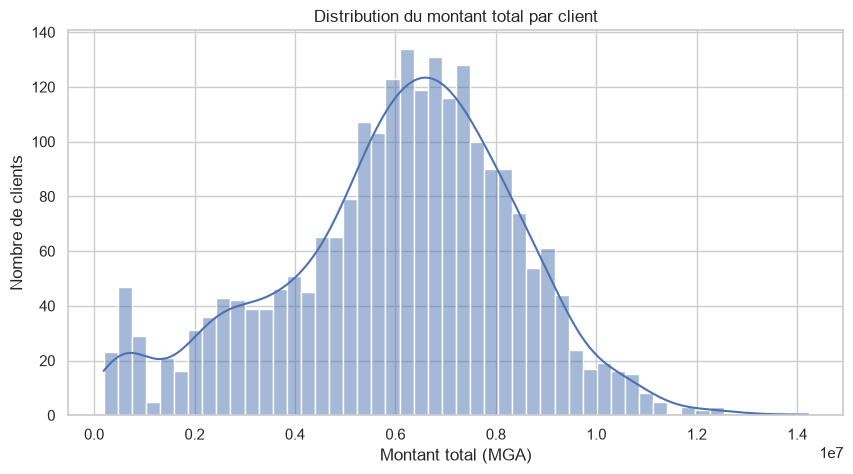

In [31]:
plt.figure(figsize=(10, 5))

sns.histplot(
    customer_features["total_amount"],
    bins=50,
    kde=True
)

plt.title("Distribution du montant total par client")
plt.xlabel("Montant total (MGA)")
plt.ylabel("Nombre de clients")

plt.show()

#### 30. SÉLECTION DES FEATURES ML
Préparation des données pour Isolation Forest

In [32]:
FEATURE_COLUMNS = [
    "outgoing_count",
    "outgoing_total",
    "outgoing_mean",
    "outgoing_max",
    "outgoing_counterparties",
    "incoming_count",
    "incoming_total",
    "incoming_mean",
    "incoming_max",
    "incoming_counterparties",
    "total_transactions",
    "total_amount",
    "outgoing_incoming_ratio"
]

# Copie des features
X = customer_features[FEATURE_COLUMNS].copy()

# Vérification des valeurs infinies
X = X.replace(
    [np.inf, -np.inf],
    np.nan
)

# Remplacement des valeurs manquantes
X = X.fillna(0)

# Dimensions (lignes, colonnes)
print("Dimensions de la matrice ML :", X.shape)

display(X.head())

Dimensions de la matrice ML : (2312, 13)


,outgoing_count,outgoing_total,outgoing_mean,outgoing_max,outgoing_counterparties,incoming_count,incoming_total,incoming_mean,incoming_max,incoming_counterparties,total_transactions,total_amount,outgoing_incoming_ratio
customer_id,,,,,,,,,,,,,
CUS00001,22.0,4775900.0,217086.363636,732200.0,22.0,20.0,2950500.0,147525.000000,435700.0,20.0,42.0,7726400.0,1.618675
CUS00002,22.0,3236000.0,147090.909091,416400.0,22.0,15.0,2618400.0,174560.000000,408000.0,15.0,37.0,5854400.0,1.235869
CUS00003,17.0,4403600.0,259035.294118,1499700.0,17.0,18.0,3656200.0,203122.222222,814600.0,18.0,35.0,8059800.0,1.204420
CUS00004,23.0,3258600.0,141678.260870,402500.0,23.0,15.0,2215800.0,147720.000000,858800.0,15.0,38.0,5474400.0,1.470620
CUS00005,18.0,2822900.0,156827.777778,459500.0,18.0,14.0,1945700.0,138978.571429,333000.0,14.0,32.0,4768600.0,1.450840


#### 31. NORMALISATION DES FEATURES

In [33]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# Conversion en DataFrame pour conserver les noms des features
X_scaled = pd.DataFrame(
    X_scaled,
    columns=FEATURE_COLUMNS,
    index=X.index
)

print("Normalisation terminée.")

display(X_scaled.head())

Normalisation terminée.


,outgoing_count,outgoing_total,outgoing_mean,outgoing_max,outgoing_counterparties,incoming_count,incoming_total,incoming_mean,incoming_max,incoming_counterparties,total_transactions,total_amount,outgoing_incoming_ratio
customer_id,,,,,,,,,,,,,
CUS00001,0.563203,0.926816,0.348061,0.282379,0.574439,0.643625,-0.054696,-0.268826,-0.546135,0.662000,0.734819,0.714023,0.575734
CUS00002,0.563203,0.114922,-0.088561,-0.363407,0.574439,-0.300936,-0.323681,-0.093949,-0.609660,-0.286998,0.317972,-0.076736,0.154802
CUS00003,0.042395,0.730526,0.609733,1.851857,0.051069,0.265801,0.516886,0.090808,0.322811,0.282401,0.151233,0.854856,0.120220
CUS00004,0.667365,0.126838,-0.122325,-0.391832,0.679113,-0.300936,-0.649767,-0.267565,0.424176,-0.286998,0.401341,-0.237253,0.412934
CUS00005,0.146556,-0.102880,-0.027824,-0.275271,0.155743,-0.489848,-0.868535,-0.324110,-0.781660,-0.476798,-0.098875,-0.535393,0.391184


#### 32. ENTRAÎNEMENT ISOLATION FOREST

In [34]:
# Initialisation du modèle
isolation_forest = IsolationForest(
    n_estimators=200,
    contamination=CONTAMINATION,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# Entraînement du modèle non supervisé
isolation_forest.fit(X_scaled)

print("Modèle Isolation Forest entraîné.")

Modèle Isolation Forest entraîné.


#### 33. SCORES D'ANOMALIE

In [35]:
# Score brut du modèle
# Plus le score est faible, plus le comportement est atypique
anomaly_scores = isolation_forest.decision_function(
    X_scaled
)

# Prédiction
#  1 = comportement normal
# -1 = anomalie
anomaly_predictions = isolation_forest.predict(
    X_scaled
)

# Création du DataFrame de résultats
df_anomalies = customer_features.copy()

df_anomalies["anomaly_score"] = anomaly_scores

df_anomalies["anomaly_label"] = (
    anomaly_predictions == -1
)

# Extraction des clients atypiques
df_anomalies_detected = df_anomalies[
    df_anomalies["anomaly_label"]
].copy()

print(
    "Nombre de clients atypiques :",
    len(df_anomalies_detected)
)

display(
    df_anomalies_detected.sort_values(
        "anomaly_score"
    ).head(20)
)

Nombre de clients atypiques : 47


,outgoing_count,outgoing_total,outgoing_mean,outgoing_max,outgoing_counterparties,incoming_count,incoming_total,incoming_mean,incoming_max,incoming_counterparties,total_transactions,total_amount,outgoing_incoming_ratio,anomaly_score,anomaly_label
customer_id,,,,,,,,,,,,,,,
CUS_PASS_OUT_00,0.0,0.0,0.000000e+00,0.0,0.0,1.0,3100000.0,3.100000e+06,3100000.0,1.0,1.0,3100000.0,0.000000,-0.059078,True
CUS_PASS_OUT_01,0.0,0.0,0.000000e+00,0.0,0.0,1.0,3100000.0,3.100000e+06,3100000.0,1.0,1.0,3100000.0,0.000000,-0.059078,True
CUS_PASS_OUT_02,0.0,0.0,0.000000e+00,0.0,0.0,1.0,3100000.0,3.100000e+06,3100000.0,1.0,1.0,3100000.0,0.000000,-0.059078,True
CUS_PASS_OUT_03,0.0,0.0,0.000000e+00,0.0,0.0,1.0,3100000.0,3.100000e+06,3100000.0,1.0,1.0,3100000.0,0.000000,-0.059078,True
CUS_PASS_00,1.0,3100000.0,3.100000e+06,3100000.0,1.0,7.0,3500000.0,5.000000e+05,500000.0,7.0,8.0,6600000.0,0.885714,-0.058875,True
CUS_PASS_01,1.0,3100000.0,3.100000e+06,3100000.0,1.0,7.0,3500000.0,5.000000e+05,500000.0,7.0,8.0,6600000.0,0.885714,-0.058875,True
CUS_PASS_02,1.0,3100000.0,3.100000e+06,3100000.0,1.0,7.0,3500000.0,5.000000e+05,500000.0,7.0,8.0,6600000.0,0.885714,-0.058875,True
CUS_PASS_03,1.0,3100000.0,3.100000e+06,3100000.0,1.0,7.0,3500000.0,5.000000e+05,500000.0,7.0,8.0,6600000.0,0.885714,-0.058875,True
CUS_STRUCT_00,7.0,6048669.0,8.640956e+05,923855.0,7.0,0.0,0.0,0.000000e+00,0.0,0.0,7.0,6048669.0,0.000000,-0.055987,True


#### 34. VISUALISATION DES CLIENTS ATYPIQUES

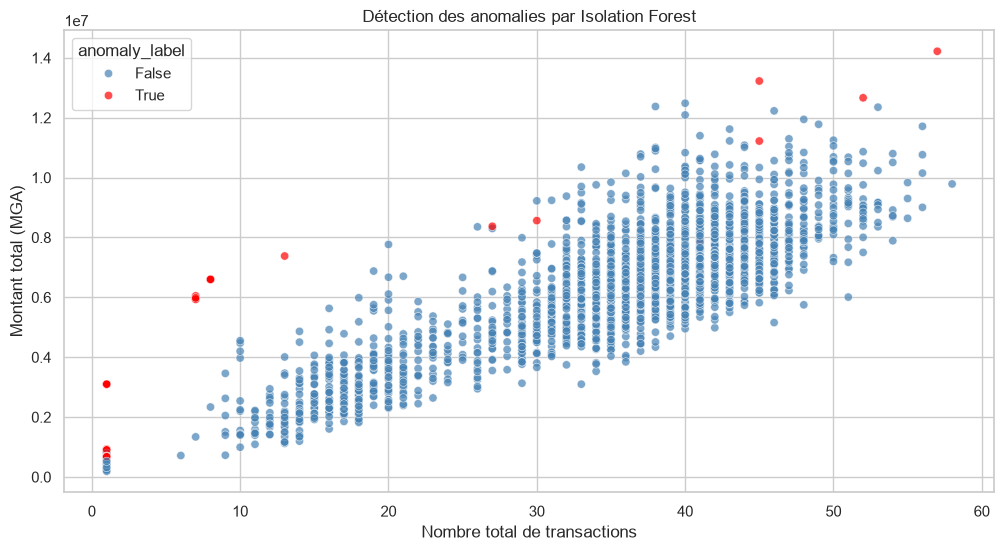

In [36]:
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=df_anomalies,
    x="total_transactions",
    y="total_amount",
    hue="anomaly_label",
    palette={
        False: "steelblue",
        True: "red"
    },
    alpha=0.7
)

plt.title("Détection des anomalies par Isolation Forest")
plt.xlabel("Nombre total de transactions")
plt.ylabel("Montant total (MGA)")

plt.show()

#### 35. COMPARAISON RÈGLES AML VS MACHINE LEARNING
Nous allons vérifier :
- Les clients détectés par les règles.
- Les clients détectés par Isolation Forest.
- Les clients détectés par les deux approches.
- Les anomalies ML qui ne sont pas encore détectées par les règles.

In [37]:
# Extraction des clients signalés par les règles
if not alerts_deduplicated.empty:

    rule_customers = set(
        alerts_deduplicated["customer_id"].astype(str)
    )

else:

    rule_customers = set()


# Extraction des clients signalés par Isolation Forest
ml_customers = set(
    df_anomalies_detected.index.astype(str)
)


# Clients détectés par les deux approches
common_customers = (
    rule_customers & ml_customers
)

# Clients détectés uniquement par les règles
rules_only = (
    rule_customers - ml_customers
)

# Clients détectés uniquement par ML
ml_only = (
    ml_customers - rule_customers
)


# Synthèse
comparison = pd.DataFrame({
    "category": [
        "Détectés par les règles",
        "Détectés par ML",
        "Détectés par les deux",
        "Règles uniquement",
        "ML uniquement"
    ],

    "customer_count": [
        len(rule_customers),
        len(ml_customers),
        len(common_customers),
        len(rules_only),
        len(ml_only)
    ]
})

display(comparison)

,category,customer_count
0,Détectés par les règles,52
1,Détectés par ML,47
2,Détectés par les deux,8
3,Règles uniquement,44
4,ML uniquement,39


#### 36. EXPORT DES ANOMALIES ML

In [38]:
df_anomalies_detected.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "customer_anomalies.csv"
    ),
    index=True,
    encoding="utf-8"
)

print(
    "Fichier customer_anomalies.csv généré."
)

Fichier customer_anomalies.csv généré.
